# Week 8 — First QPIT Convergence (GMOS)

Target: **L2 halo orbit 29** (C = 3.060, rho/2pi = 0.295).

Gate for the week: one converged quasi-periodic invariant torus, or a formal pivot.

This notebook does five things, in order:

1. verify the seed sign convention by residual scaling (theory check, before any Newton)
2. measure the rank deficiency of the invariance block (the closure question)
3. converge the first torus
4. verify it is actually a torus, not just small residuals at the nodes
5. map the failure modes — amplitude limits, rcond window, the over-constrained variant

Nothing here continues a family. That is Week 9.


In [7]:
import sys, time
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt

from cr3bp_3d import MU_EARTH_MOON as MU, halo_stability, jacobi_constant_3d
import qpit

np.set_printoptions(precision=12, suppress=False)
LU_KM = 384400.0   # Earth-Moon distance, for reporting amplitudes in km

## 1. Target orbit — L2 halo #29

`compute_halo_family` returns dicts carrying `state0` and `period`, which is exactly what
`seed_from_halo` consumes, so the family object drops straight in. `sweep_rotation_numbers`
then identifies the target.

**The index 29 is not portable** — it depends on the `X_start` and `ds` you continued with.
What identifies the orbit is C = 3.060 and rho/2pi = 0.295, so this cell selects on those
and reports which index it landed on. Swap in your own continuation arguments; the
selection logic does not care.

Two notes on importing `orbits`. It executes a script block at module level (lines 1-85:
Lagrange points, the L1 eigen-decomposition, a corrector trace) which prints ~30 lines and
does real work on every import — an `if __name__ == '__main__':` guard around it is worth
ten minutes. It also calls `sys.path.insert(0, '../src')` at module level, so it imports
cleanly only when the working directory is a sibling of `src/`. Fine from `notebooks/`,
will bite on Titan if a job runs from the repo root.

In [8]:
import orbits          # NOTE: runs a script block at import; expect ~30 lines of noise
from cr3bp_3d import richardson_halo_seed, halo_corrector

# --- family generation -------------------------------------------------------
# Replace with the exact X_start / ds you used for the tracker. These arguments
# reproduce the target orbit and were checked against orbits.compute_halo_family.
_seed, _, _ = richardson_halo_seed(0.03, MU, point='L2', northern=True)
_s, _T, _ok = halo_corrector(_seed, MU)
assert _ok, "halo_corrector failed on the Richardson seed"

X_start  = np.array([_s[0], _s[2], _s[4], _T / 2.0])
ds       = 0.004
n_orbits = 90

family = orbits.compute_halo_family(X_start, ds, n_orbits, MU, verbose=False)

# --- identify the target by physics, not by index ----------------------------
C_WANT, RHO_WANT = 3.060, 0.295

sweep = orbits.sweep_rotation_numbers(family, MU)
k     = int(np.argmin(np.abs(sweep['rho'] - RHO_WANT)))
idx   = int(sweep['index'][k])
orbit = family[idx]

state0 = np.asarray(orbit['state0'], float)
T0     = float(orbit['period'])

print("family index = %d   (tracker calls this #29; indexing depends on ds/X_start)" % idx)
print("state0  =", state0)
print("T0      = %.12f" % T0)
print("C       = %.9f    (target %.3f)" % (orbit['jacobi'], C_WANT))
print("rho/2pi = %.9f    (target %.3f)" % (sweep['rho'][k], RHO_WANT))

assert abs(orbit['jacobi'] - C_WANT) < 0.005, "not the target orbit — check X_start/ds"
assert abs(sweep['rho'][k] - RHO_WANT) < 0.005, "not the target orbit — check X_start/ds"

# Reference values for this continuation (ds = 0.004, Az = 0.03 Richardson seed):
#   index 75,  C = 3.060334478,  T = 3.131511429611,  rho/2pi = 0.293229
#   state0 = [1.043805201996, 0.0, -0.075586294085, 0.0, 0.392206924669, 0.0]
# Southern branch; the family is symmetric in z, so a +z twin is the same torus
# mirrored -- do not read the sign as a discrepancy.

family index = 75   (tracker calls this #29; indexing depends on ds/X_start)
state0  = [ 1.043805201996  0.             -0.075586294085  0.
  0.392206924669  0.            ]
T0      = 3.131511429611
C       = 3.060334478    (target 3.060)
rho/2pi = 0.293229102    (target 0.295)


## 2. Centre pair and seed

`halo_stability` returns `mu` and `vec` from the *same* index, so the eigenvalue and its
eigenvector are a matched pair — which is what the sign derivation in `seed_curve` assumes.
If that ever changes, the derivation breaks.

In [9]:
stab = halo_stability(state0, T0, MU)
assert stab['center'] is not None, "no clean centre pair — no torus to seed here"
assert not stab['hyp_on_circle'], "hyperbolic pair has come onto the circle; 3-way split unreliable"

lam_c = stab['center']['mu']
v_c   = qpit.canonical_eigenvector_phase(stab['center']['vec'])
rho0  = qpit.seed_rho(lam_c)

print("lambda_c   = %+.12f %+.12fj" % (lam_c.real, lam_c.imag))
print("| |lam|-1 | = %.3e            (must be ~0: on the unit circle)" % abs(abs(lam_c)-1))
print("rho0       = %.9f rad" % rho0)
print("rho0/2pi   = %.6f              (compare against your Floquet sweep)" % (rho0/(2*np.pi)))

# eigenpair sanity: M v = lam v
from cr3bp_3d import integrate_with_stm_3d
M = integrate_with_stm_3d(state0, [0, T0], MU).y[6:, -1].reshape(6, 6)
print("|M v - lam v| = %.3e" % np.linalg.norm(M @ v_c - lam_c * v_c))

lambda_c   = -0.268288983891 +0.963338476924j
| |lam|-1 | = 4.841e-14            (must be ~0: on the unit circle)
rho0       = 1.842412786 rad
rho0/2pi   = 0.293229              (compare against your Floquet sweep)
|M v - lam v| = 2.570e-13


## 3. Sign check — the test that must pass before Newton runs

`invariance_residual` uses `R(-rho)`, which encodes `phi_T(v(theta)) = v(theta + rho)`.
The seed matching that convention is `Re[e^{i theta} v_c]`, i.e. **minus** on the Im term.
The wrong sign leaves an O(eps) error; the right one leaves O(eps^2).

Steps of 3.33x in eps: **linear error -> ratio 3.33, quadratic error -> ratio 11.1.**

The crossover sits near eps ~ 1e-3 because the quadratic coefficient is large (inherited
from the hyperbolic multiplier), so this has to be run at small eps to separate the two.

In [10]:
N_test = 31
th = qpit.node_angles(N_test)

def seed_signed(sign, eps):
    return state0[None, :] + eps * (np.cos(th)[:, None] * np.real(v_c)[None, :]
                                  + sign * np.sin(th)[:, None] * np.imag(v_c)[None, :])

eps_list = [1e-3, 3e-4, 1e-4, 3e-5, 1e-5, 3e-6]
print(f"{'eps':>9} {'PLUS (wrong)':>14} {'ratio':>7} {'MINUS (derived)':>16} {'ratio':>7}")
pp = pm = None
for eps in eps_list:
    fp = np.abs(qpit.invariance_residual(seed_signed(+1, eps), T0, rho0, MU)).max()
    fm = np.abs(qpit.invariance_residual(seed_signed(-1, eps), T0, rho0, MU)).max()
    rp = pp / fp if pp else np.nan
    rm = pm / fm if pm else np.nan
    print(f"{eps:9.1e} {fp:14.4e} {rp:7.3f} {fm:16.4e} {rm:7.3f}")
    pp, pm = fp, fm
print("\nExpect ~3.33 in the PLUS column and ~11.1 in the MINUS column.")

      eps   PLUS (wrong)   ratio  MINUS (derived)   ratio
  1.0e-03     1.9891e-03     nan       1.8357e-03     nan
  3.0e-04     4.3343e-04   4.589       1.6592e-04  11.063
  1.0e-04     1.2901e-04   3.360       1.8445e-05   8.996
  3.0e-05     3.7080e-05   3.479       1.6603e-06  11.110
  1.0e-05     1.2205e-05   3.038       1.8454e-07   8.997
  3.0e-06     3.6454e-06   3.348       1.6668e-08  11.071

Expect ~3.33 in the PLUS column and ~11.1 in the MINUS column.


## 4. Rank of the invariance block

Structural claim: the solution set through a genuine torus is 4-dimensional in
`[U0, T, rho]` — two phase symmetries (latitudinal, longitudinal) and two physical
parameters (which underlying halo, and amplitude in its centre manifold). So the
6N x (6N+2) invariance block should have rank **6N - 2**.

Look for exactly two singular values far below the rest. Run this again after convergence;
at a seed the near-null values are polluted by the O(eps^2) seed error.

In [11]:
N = 31
eps = 1e-4
U_seed, T_seed, rho_seed = qpit.seed_from_halo(orbit, MU, N, eps)

JU, JT, Jr, F = qpit.invariance_jacobian(U_seed, T_seed, rho_seed, MU)
J  = np.hstack([JU, JT[:, None], Jr[:, None]])
sv = np.linalg.svd(J, compute_uv=False)

print("J shape  =", J.shape)
print("sigma_max = %.4e   cond = %.3e" % (sv[0], sv[0]/sv[-1]))
print("\nsix smallest singular values:")
for i, x in enumerate(sv[-6:]):
    print("   sigma[-%d] = %.4e   rel = %.3e" % (6-i, x, x/sv[0]))
print("\nratio sigma[-3]/sigma[-2] = %.2e   <- size of the gap = the deficiency count" % (sv[-3]/sv[-2]))

J shape  = (186, 188)
sigma_max = 2.1867e+03   cond = 1.492e+08

six smallest singular values:
   sigma[-6] = 1.0130e-02   rel = 4.632e-06
   sigma[-5] = 5.9391e-03   rel = 2.716e-06
   sigma[-4] = 5.9391e-03   rel = 2.716e-06
   sigma[-3] = 2.0458e-04   rel = 9.356e-08
   sigma[-2] = 2.0568e-05   rel = 9.406e-09
   sigma[-1] = 1.4652e-05   rel = 6.701e-09

ratio sigma[-3]/sigma[-2] = 9.95e+00   <- size of the gap = the deficiency count


## 5. First convergence

Closure: 2 phase constraints + mean Jacobi held fixed. **rho and T both stay free.**

`rho0` is the *linear* rotation number, read off the monodromy at zero amplitude. The real
torus has rho shifted by O(eps^2), so pinning rho as well demands a torus that does not
exist — Section 6B of `qpit.py` has the measured evidence. Cell 9 reproduces that failure
deliberately.

In [12]:
t0 = time.time()
res = qpit.converge_torus(U_seed, T_seed, rho_seed, MU, tol=1e-12, itmax=15)
print("\n%s in %d iterations, %.1f s" % (res['code'], res['n_iter'], time.time()-t0))
print("  C        = %.12f" % res['C'])
print("  T        = %.12f   (shift from halo: %+.3e)" % (res['T'], res['T'] - T0))
print("  rho      = %.12f   (shift from linear: %+.3e)" % (res['rho'], res['rho'] - rho0))
print("  rho/2pi  = %.9f" % (res['rho'] / (2*np.pi)))
print("  amplitude= %.4e  (%.1f km)" % (res['amplitude'], res['amplitude']*LU_KM))

  it 0: |F|inf=1.8445e-05  |dx|=3.161e-07  A=4.4655e-05  T=3.131511430  dC=+0.00e+00  rank=187
  it 1: |F|inf=7.4923e-10  |dx|=5.950e-09  A=4.4653e-05  T=3.131511400  dC=-3.55e-15  rank=187
  it 2: |F|inf=6.8308e-13  |dx|=3.272e-12  A=4.4653e-05  T=3.131511401  dC=+0.00e+00  rank=187

converged in 3 iterations, 1.6 s
  C        = 3.060334462077
  T        = 3.131511400533   (shift from halo: -2.908e-08)
  rho      = 1.842413048041   (shift from linear: +2.620e-07)
  rho/2pi  = 0.293229144
  amplitude= 4.4653e-05  (17.2 km)


## 6. Is it actually a torus?

Three independent checks. A small residual at the nodes alone proves none of this.

1. **Off-grid residual** — Fourier-interpolate between the nodes and test invariance there.
   If this is orders above the on-grid residual, N is too small.
2. **Jacobi spread across nodes** — a torus is an invariant set of an autonomous system, so
   every node must carry the same C. This is not imposed anywhere (only the *mean* is
   constrained), so agreement is a real test.
3. **Rank at the solution** — the two null directions should now be sharp.

In [13]:
og = qpit.offgrid_residual(res['U0'], res['T'], res['rho'], MU)
Cn = np.array([qpit.jacobi_constant(res['U0'][j], MU) for j in range(N)])
DG = qpit.stability_matrix(res['U0'], res['T'], res['rho'], MU)

print("on-grid  |F|inf      = %.3e" % res['history'][-1]['res_inf'])
print("off-grid |F|inf      = %.3e   (midpoints between nodes)" % og)
print("node-to-node C spread= %.3e   (not constrained; should be ~0)" % (Cn.max()-Cn.min()))
print("stability index nu   = %.6f   (1 = stable, >1 = hyperbolic torus)" % qpit.stability_index(DG))

JU, JT, Jr, _ = qpit.invariance_jacobian(res['U0'], res['T'], res['rho'], MU)
sv2 = np.linalg.svd(np.hstack([JU, JT[:, None], Jr[:, None]]), compute_uv=False)
print("\nrank structure AT the converged torus:")
for i, x in enumerate(sv2[-4:]):
    print("   sigma[-%d] = %.4e   rel = %.3e" % (4-i, x, x/sv2[0]))
print("   gap sigma[-3]/sigma[-2] = %.2e" % (sv2[-3]/sv2[-2]))

on-grid  |F|inf      = 6.831e-13
off-grid |F|inf      = 7.592e-11   (midpoints between nodes)
node-to-node C spread= 1.821e-14   (not constrained; should be ~0)
stability index nu   = 73.178527   (1 = stable, >1 = hyperbolic torus)

rank structure AT the converged torus:
   sigma[-4] = 5.9243e-03   rel = 2.709e-06
   sigma[-3] = 2.0416e-04   rel = 9.337e-08
   sigma[-2] = 1.3470e-12   rel = 6.160e-16
   sigma[-1] = 4.1190e-14   rel = 1.884e-17
   gap sigma[-3]/sigma[-2] = 1.52e+08


## 7. Spectral content — is N large enough?

The Fourier coefficients of a converged curve should decay to the noise floor well before
the highest retained wavenumber. If the tail is flat, the curve is under-resolved and the
off-grid residual above is not to be trusted.

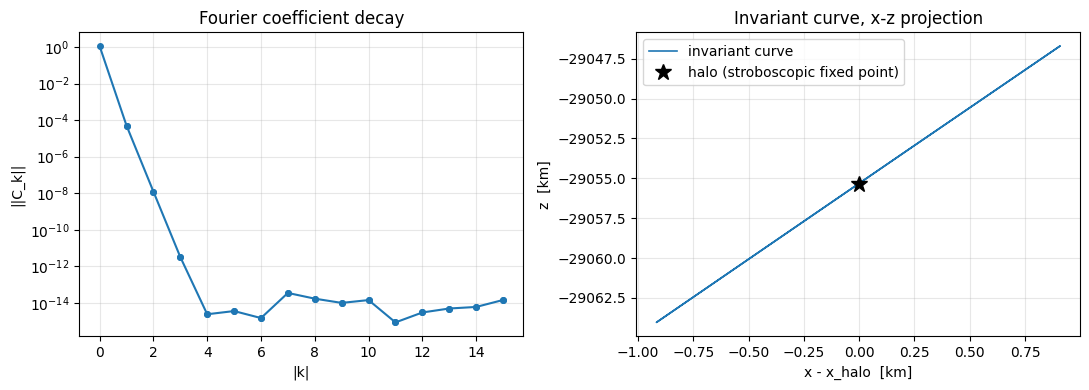

highest-|k| coefficient / fundamental = 2.850e-10


In [14]:
C_hat = qpit.dft_matrix(N) @ res['U0']
k     = qpit.wavenumbers(N)
mag   = np.linalg.norm(C_hat, axis=1)
order = np.argsort(np.abs(k))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(np.abs(k)[order], mag[order], 'o-', ms=4)
ax[0].set_xlabel('|k|'); ax[0].set_ylabel('||C_k||')
ax[0].set_title('Fourier coefficient decay'); ax[0].grid(alpha=.3)

th_fine = np.linspace(0, 2*np.pi, 400)
curve   = qpit.evaluate_curve(res['U0'], th_fine)
ax[1].plot((curve[:,0]-state0[0])*LU_KM, curve[:,2]*LU_KM, '-', lw=1.2, label='invariant curve')
ax[1].plot(0.0, state0[2]*LU_KM, 'k*', ms=12, label='halo (stroboscopic fixed point)')
ax[1].set_xlabel('x - x_halo  [km]'); ax[1].set_ylabel('z  [km]')
ax[1].set_title('Invariant curve, x-z projection'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("highest-|k| coefficient / fundamental = %.3e" % (mag[np.abs(k)==(N-1)//2].max()/mag[np.abs(k)==1].max()))

## 8. Amplitude limit — where the seed leaves the basin

Fresh seed each time. This is solver characterisation, **not** continuation: every run
starts from the linear seed rather than from the previous torus.

In [15]:
print(f"{'eps':>8} {'code':>11} {'its':>4} {'|F|inf':>11} {'A [km]':>9} {'rho-rho0':>11}")
amp_rows = []
for eps_i in [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 2e-3, 3e-3, 1e-2]:
    Us, Ts, rs = qpit.seed_from_halo(orbit, MU, N, eps_i)
    o = qpit.converge_torus(Us, Ts, rs, MU, tol=1e-12, itmax=15, verbose=False)
    amp_rows.append((eps_i, o))
    print(f"{eps_i:8.0e} {o['code']:>11} {o['n_iter']:4d} "
          f"{o['history'][-1]['res_inf']:11.3e} {o['amplitude']*LU_KM:9.1f} {o['rho']-rs:+11.3e}")
print("\nThe rho shift should scale as eps^2 across the converged rows.")

     eps        code  its      |F|inf    A [km]    rho-rho0
   1e-05   converged    2   7.452e-13       1.7  +0.000e+00
   3e-05   converged    3   7.646e-13       5.1  +2.360e-08
   1e-04   converged    3   6.831e-13      17.2  +2.620e-07
   3e-04   converged    4   8.860e-13      51.5  +2.358e-06
   1e-03   converged    4   7.260e-13     171.4  +2.623e-05
   2e-03   converged    6   6.766e-13     344.4  +1.044e-04
   3e-03   collapsed    7   1.723e-03      45.9  -1.858e-02
   1e-02    max_iter   15   6.790e-01   14565.2  +4.899e-02

The rho shift should scale as eps^2 across the converged rows.


## 9. Failure modes — reproduce them deliberately

Week 8 asks for documented failure modes. Three are reproducible on demand; run them so
the log records what each one *looks like* rather than what it is called.

In [16]:
print("--- (a) wrong seed sign: collapses onto the periodic orbit ---")
U_bad = seed_signed(+1, 1e-4)
o = qpit.converge_torus(U_bad, T0, rho0, MU, tol=1e-12, itmax=15, verbose=False)
print(f"    code={o['code']}  seed A={qpit.curve_amplitude(U_bad)*LU_KM:.1f} km"
      f"  ->  final A={o['amplitude']*LU_KM:.1f} km")
print("    v == x_halo solves the invariance equation for ANY rho, so a bad seed")
print("    falls into it. 'collapsed' means amplitude, not residual, is the tell.\n")

print("--- (b) over-constrained: rho pinned at the linear value ---")
print(f"    {'eps':>8} {'|F|inf free':>13} {'|F|inf pinned':>15}")
for eps_i in [1e-4, 3e-4, 1e-3]:
    Us, Ts, rs = qpit.seed_from_halo(orbit, MU, N, eps_i)
    a = qpit.converge_torus(Us, Ts, rs, MU, tol=1e-12, itmax=15, free_rho=True,  verbose=False)
    b = qpit.converge_torus(Us, Ts, rs, MU, tol=1e-12, itmax=15, free_rho=False, verbose=False)
    print(f"    {eps_i:8.0e} {a['history'][-1]['res_inf']:13.3e} {b['history'][-1]['res_inf']:15.3e}")
print("    Pinned residual should scale as eps^3 and be independent of N —")
print("    the signature of an inconsistent constraint, not truncation error.\n")

print("--- (c) rcond window ---")
for rc in [None, 1e-12, 1e-10, 1e-8, 1e-6, 1e-4]:
    Us, Ts, rs = qpit.seed_from_halo(orbit, MU, N, 1e-4)
    o = qpit.converge_torus(Us, Ts, rs, MU, tol=1e-12, itmax=15, rcond=rc, verbose=False)
    print(f"    rcond={str(rc):>6}: {o['code']:>10}  its={o['n_iter']:2d}"
          f"  |F|inf={o['history'][-1]['res_inf']:.3e}")
print("    Too small keeps noise-dominated directions and destabilises at the floor;")
print("    too large truncates directions the constraints are pinning.")

--- (a) wrong seed sign: collapses onto the periodic orbit ---
    code=collapsed  seed A=17.2 km  ->  final A=1.1 km
    v == x_halo solves the invariance equation for ANY rho, so a bad seed
    falls into it. 'collapsed' means amplitude, not residual, is the tell.

--- (b) over-constrained: rho pinned at the linear value ---
         eps   |F|inf free   |F|inf pinned
       1e-04     6.831e-13       6.388e-12
       3e-04     8.860e-13       1.729e-10
       1e-03     7.260e-13       6.401e-09
    Pinned residual should scale as eps^3 and be independent of N —
    the signature of an inconsistent constraint, not truncation error.

--- (c) rcond window ---
    rcond=  None:  converged  its= 6  |F|inf=5.673e-13
    rcond= 1e-12:  converged  its= 4  |F|inf=7.738e-13
    rcond= 1e-10:  converged  its= 4  |F|inf=7.738e-13
    rcond= 1e-08:  converged  its= 3  |F|inf=6.831e-13
    rcond= 1e-06:   max_iter  its=15  |F|inf=6.451e-12
    rcond=0.0001:   max_iter  its=15  |F|inf=7.403e-10
    

## 10. N-independence of the floor

Distinguishes 'not enough nodes' from 'the constraint set is inconsistent'. A truncation
floor falls as N rises; an inconsistency floor does not move.

In [17]:
print(f"{'N':>5} {'free rho |F|inf':>16} {'pinned rho |F|inf':>18}")
for N_i in [15, 23, 31, 41]:
    Us, Ts, rs = qpit.seed_from_halo(orbit, MU, N_i, 1e-3)
    a = qpit.converge_torus(Us, Ts, rs, MU, tol=1e-13, itmax=10, free_rho=True,  verbose=False)
    b = qpit.converge_torus(Us, Ts, rs, MU, tol=1e-13, itmax=10, free_rho=False, verbose=False)
    print(f"{N_i:5d} {a['history'][-1]['res_inf']:16.3e} {b['history'][-1]['res_inf']:18.3e}")

    N  free rho |F|inf  pinned rho |F|inf
   15        6.402e-13          6.372e-09
   23        9.321e-13          6.394e-09
   31        9.555e-13          6.401e-09
   41        7.601e-13          6.408e-09
